# Sesión 12 · Notebook de clase · Series de tiempo

**Fundamentos de Ciencia de Datos e IA (CDIAG1003)** · Semana 7 · Unidad 3, tema 3.5: fechas en pandas, índice temporal, `resample`, medias móviles, estacionalidad a simple vista y gráficos de series.

Hasta ahora las filas de una tabla no tenían orden: daba igual leerlas de arriba abajo o al revés. Cuando una columna es una **fecha**, el orden importa: aparece la pregunta «¿cómo **cambia** esto con el tiempo?» (¿crece?, ¿tiene temporada?, ¿qué día de la semana es más fuerte?, ¿qué pasó en diciembre?). Hoy: cómo pandas entiende las fechas, cómo cambiar de **frecuencia** (de días a semanas o meses), cómo ver la **tendencia** detrás del ruido y cómo descubrir el **patrón que se repite**.

Datos, en la carpeta `datos/`:

| Archivo | Qué es |
| :-- | :-- |
| `ventas_diarias.csv` | **nuevo**: el histórico **diario** de la tienda de la sesión 9 en 2024 y 2025: 720 días con `n_ventas`, `ingreso` (dólares) y `promocion` (1 si hubo promoción). Empieza el 2 de enero de 2024 y faltan 10 días: 7 de cierre (Viernes Santo, 1 de mayo y Navidad de cada año, y el 1 de enero de 2025) y un hueco de 3 días en septiembre de 2025 (sistema caído) |
| `ventas_completo.csv` | las 260 ventas detalladas de enero a abril de 2026 (sesión 9) |
| `cosechas.csv` | 480 ciclos de camarón con su `fecha_siembra` (sesión 10) |
| `entregas.csv` | 420 entregas de mensajería de julio y agosto de 2026 (Taller 3) |

**Cómo trabajar con este notebook**
- Ejecute las celdas en orden. En los ejercicios **Su turno**, reemplace los `...`; la celda `assert` siguiente comprueba el resultado.
- Todo gráfico lleva título y etiquetas con unidad en los dos ejes (regla de la sesión 10).
- Las salidas de la versión resuelta están en pandas 3; en pandas 2 el texto aparece como `object` y algún aviso (`FutureWarning`) puede variar.

In [2]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

vd = pd.read_csv("datos/ventas_diarias.csv", parse_dates=["fecha"])    # parse_dates: la columna llega como fecha, no como texto
v = pd.read_csv("datos/ventas_completo.csv", parse_dates=["fecha"])
c = pd.read_csv("datos/cosechas.csv", parse_dates=["fecha_siembra"])
e = pd.read_csv("datos/entregas.csv", parse_dates=["fecha"])
print("ventas_diarias:", vd.shape, "| ventas_completo:", v.shape, "| cosechas:", c.shape, "| entregas:", e.shape)
vd.head()

ventas_diarias: (720, 4) | ventas_completo: (260, 13) | cosechas: (480, 13) | entregas: (420, 9)


,fecha,n_ventas,ingreso,promocion
0,2024-01-02,23,439.30,0
1,2024-01-03,20,355.20,0
2,2024-01-04,22,386.84,0
3,2024-01-05,31,516.16,0
4,2024-01-06,37,640.96,0


## 1. Fechas en pandas: `datetime64`, `to_datetime` y el accesor `.dt`

Un archivo CSV guarda las fechas como **texto** (`"2024-01-02"`). Para que pandas pueda ordenarlas, restarlas o agruparlas por mes hay que convertirlas al tipo **`datetime64`**: con `parse_dates=` al leer (como arriba) o con `pd.to_datetime(columna)` después. Si el texto no está en formato ISO (`AAAA-MM-DD`), se indica el formato: `pd.to_datetime(s, format="%d/%m/%Y")` para `05/11/2026`.

Una vez convertida, el accesor **`.dt`** saca las partes de la fecha: `.dt.year`, `.dt.month`, `.dt.day`, `.dt.dayofweek` (0 = lunes … 6 = domingo), `.dt.day_name()`, `.dt.to_period("M")` (el mes como periodo). Y las fechas se **restan**: la diferencia es un `Timedelta` (`.dt.days` da los días).

In [3]:
print(vd.dtypes, "\n")
print("tipo de la columna fecha:", vd["fecha"].dtype)
print("primera y última fecha:", vd["fecha"].min().date(), "→", vd["fecha"].max().date())
print("días que abarca:", (vd["fecha"].max() - vd["fecha"].min()).days + 1, "| filas:", len(vd), "(faltan algunos días: sección 2)")

fecha        datetime64[us]
n_ventas              int64
ingreso             float64
promocion             int64
dtype: object 

tipo de la columna fecha: datetime64[us]
primera y última fecha: 2024-01-02 → 2025-12-31
días que abarca: 730 | filas: 720 (faltan algunos días: sección 2)


In [4]:
# Texto -> fecha, con y sin formato explícito
texto = pd.Series(["2026-11-09", "2026-11-11"])
print(pd.to_datetime(texto).dt.day_name().tolist())     # ISO: no hace falta formato
texto2 = pd.Series(["09/11/2026", "11/11/2026"])    # día/mes/año (formato de Ecuador)
print(pd.to_datetime(texto2, format="%d/%m/%Y").dt.day_name().tolist())   # sin format= pandas puede leer 09/11 como 11 de septiembre

['Monday', 'Wednesday']
['Monday', 'Wednesday']


In [5]:
# Las partes de la fecha con .dt (0 = lunes ... 6 = domingo)
DIAS = ["lun", "mar", "mié", "jue", "vie", "sáb", "dom"]
vd["anio"] = vd["fecha"].dt.year
vd["mes"] = vd["fecha"].dt.month
vd["dia_semana"] = vd["fecha"].dt.dayofweek
vd["nombre_dia"] = vd["dia_semana"].map(dict(enumerate(DIAS)))
vd.head(7)

,fecha,n_ventas,ingreso,promocion,anio,mes,dia_semana,nombre_dia
0,2024-01-02,23,439.30,0,2024,1,1,mar
1,2024-01-03,20,355.20,0,2024,1,2,mié
2,2024-01-04,22,386.84,0,2024,1,3,jue
3,2024-01-05,31,516.16,0,2024,1,4,vie
4,2024-01-06,37,640.96,0,2024,1,5,sáb
5,2024-01-07,23,388.52,1,2024,1,6,dom
6,2024-01-08,21,353.07,0,2024,1,0,lun


Con las partes de la fecha como columnas, lo de la sesión 8 (`groupby`) ya responde preguntas de tiempo: ¿qué mes vende más?, ¿qué día de la semana? Eso sirve para **comparar periodos**; para **mirar la serie completa** hace falta el índice temporal (sección 2).

### Su turno 1.1 · 3 min
En las 260 ventas de 2026 (`v`): ¿qué **día de la semana** acumula más ingreso? Cree la columna `v["dia_semana"]` con `.dt.dayofweek`, calcule en `ingreso_dia` el ingreso total por día de la semana (`groupby` + `sum`) y guarde en `dia_top` el número del día con más ingreso (`idxmax`).

In [6]:
# TODO: reemplace los ... por su código
v["dia_semana"] = v["fecha"].dt.dayofweek
ingreso_dia = v.groupby("dia_semana")["ingreso"].sum()
dia_top = ingreso_dia.idxmax()
print(ingreso_dia.round(1).rename(index=dict(enumerate(DIAS))))
print("día con más ingreso:", DIAS[dia_top])

dia_semana
lun    1224.6
mar    1418.9
mié    1087.7
jue    1188.8
vie    1052.1
sáb    1956.0
dom    1567.1
Name: ingreso, dtype: float64
día con más ingreso: sáb


In [7]:
assert len(ingreso_dia) == 7 and np.isclose(round(ingreso_dia.max(), 1), 1956.0), "groupby('dia_semana')['ingreso'].sum()"
assert dia_top == 5, "idxmax() da el índice (el día) del valor máximo"
print("Correcto: el día con más ingreso en enero-abril de 2026 es el", DIAS[dia_top], "con", round(ingreso_dia.max(), 1), "dólares.")

Correcto: el día con más ingreso en enero-abril de 2026 es el sáb con 1956.0 dólares.


## 2. El índice temporal: seleccionar por fecha y encontrar los huecos

Cuando la fecha pasa a ser el **índice** (`set_index("fecha")`, ordenado con `sort_index()`), la tabla se convierte en una **serie de tiempo** y pandas entiende las fechas al seleccionar:

- `d.loc["2025-12"]` → todo diciembre de 2025; `d.loc["2024"]` → todo 2024 (selección por texto parcial);
- `d.loc["2025-05-08":"2025-05-11"]` → un rango de fechas, **incluidos** los dos extremos.

Y permite ver qué fechas **faltan**: `asfreq("D")` fuerza una fila por día y pone `NaN` donde no había datos. Qué hacer con un hueco depende de su **causa**: un día de cierre vale 0 (no se vendió); un día en que el sistema no registró se puede **interpolar** (`interpolate()`) o dejar en `NaN`; siempre se dice qué se hizo.

In [8]:
d = vd.set_index("fecha").sort_index()     # la fecha como índice, ordenado
#print(type(d.index).__name__, "| de", d.index.min().date(), "a", d.index.max().date())
d.loc["2025-12", ["n_ventas", "ingreso", "promocion"]].head()

,n_ventas,ingreso,promocion
fecha,,,
2025-12-01,21,367.60,0
2025-12-02,28,508.72,0
2025-12-03,27,487.07,0
2025-12-04,31,507.10,0
2025-12-05,33,543.98,0


In [9]:
# Un rango de fechas (los dos extremos incluidos): la semana del Día de la Madre de 2025
d.loc["2025-05-08":"2025-05-11", ["n_ventas", "ingreso", "nombre_dia"]]

,n_ventas,ingreso,nombre_dia
fecha,,,
2025-05-08,30,617.77,jue
2025-05-09,45,768.13,vie
2025-05-10,45,848.35,sáb
2025-05-11,25,457.22,dom


In [10]:
# ¿Qué días faltan? asfreq("D") pone una fila por día ENTRE la primera y la última fecha (NaN donde no había fecha registrada en ventas diarias)
completo = d.asfreq("D") # as frequency = Day
faltan = completo.index[completo["ingreso"].isna()]
print(len(faltan), "días sin fila:")
print([f.strftime("%Y-%m-%d (%a)") for f in faltan])

10 días sin fila:
['2024-03-29 (Fri)', '2024-05-01 (Wed)', '2024-12-25 (Wed)', '2025-01-01 (Wed)', '2025-04-18 (Fri)', '2025-05-01 (Thu)', '2025-09-16 (Tue)', '2025-09-17 (Wed)', '2025-09-18 (Thu)', '2025-12-25 (Thu)']


In [11]:
# Dos huecos, dos decisiones: los cierres valen 0; el hueco del sistema (16-18 sept. 2025) se interpola
ingreso_c = completo["ingreso"].copy()
cierres = ["2024-03-29", "2024-05-01", "2024-12-25", "2025-01-01", "2025-04-18", "2025-05-01", "2025-12-25"]
ingreso_c.loc[cierres] = 0       # tienda cerrada: no se vendió
ingreso_c = ingreso_c.interpolate()     # el hueco del sistema con NaNs: línea recta entre los vecinos
print(ingreso_c.loc["2025-09-14":"2025-09-20"].round(1))
print("\nNaN que quedan:", ingreso_c.isna().sum())
ingreso_c.loc["2025-09-14":"2025-09-20"].round(1)

fecha
2025-09-14    329.2
2025-09-15    465.8
2025-09-16    482.9
2025-09-17    499.9
2025-09-18    517.0
2025-09-19    534.1
2025-09-20    552.8
Freq: D, Name: ingreso, dtype: float64

NaN que quedan: 0


fecha
2025-09-14    329.2
2025-09-15    465.8
2025-09-16    482.9
2025-09-17    499.9
2025-09-18    517.0
2025-09-19    534.1
2025-09-20    552.8
Freq: D, Name: ingreso, dtype: float64

### Su turno 2.1 · 3 min
Con `d`: guarde en `mayo_2025` el ingreso total de mayo de 2025 (selección por texto parcial y `sum`) y en `n_faltan_2025` cuántos días de 2025 **no tienen fila**: construya todos los días del año con `pd.date_range("2025-01-01", "2025-12-31", freq="D")` y quite los que sí están con `.difference(d.index)` (`asfreq` no sirve aquí: solo rellena **entre** la primera y la última fecha que existen, y el 1 de enero de 2025 falta).

In [12]:
# TODO: reemplace los ... por su código
mayo_2025 = d.loc["2025-05"]["ingreso"].sum()
faltan_2025 = pd.date_range("2025-01-01", "2025-12-31", freq="D").difference(d.index)
n_faltan_2025 = len(faltan_2025)
print("mayo de 2025:", round(mayo_2025, 2), "dólares | días sin fila en 2025:", n_faltan_2025)

mayo de 2025: 16563.67 dólares | días sin fila en 2025: 7


In [13]:
assert np.isclose(round(mayo_2025, 2), 16563.67), "d.loc['2025-05', 'ingreso'].sum()"
assert n_faltan_2025 == 7, "len(pd.date_range('2025-01-01', '2025-12-31', freq='D').difference(d.index))"
print("Correcto: mayo de 2025 (Día de la Madre) sumó", round(mayo_2025, 2), "dólares;", n_faltan_2025, "días de 2025 no tienen fila (4 cierres + 3 del sistema):", [f.strftime("%d-%m") for f in faltan_2025])

Correcto: mayo de 2025 (Día de la Madre) sumó 16563.67 dólares; 7 días de 2025 no tienen fila (4 cierres + 3 del sistema): ['01-01', '18-04', '01-05', '16-09', '17-09', '18-09', '25-12']


## 3. Cambiar de frecuencia: `resample`

Los datos llegan **día a día**, pero las preguntas se hacen por **semana**, por **mes** o por **año**. `resample("ME")` agrupa el índice temporal en intervalos regulares (como un `groupby` por periodo) y después se elige la agregación: `.sum()` para totales, `.mean()` para promedios, `.size()` para contar filas (eventos), `.agg([...])` para varias. Alias de frecuencia habituales: `"D"` día, `"W"` semana (termina en domingo), `"ME"` fin de mes, `"QE"` trimestre, `"YE"` año.

La frecuencia **correcta** es la que responde la pregunta: el ingreso diario es ruidoso (día de la semana, promociones); el semanal ya muestra la temporada; el mensual muestra la tendencia. Más agregado = menos ruido, pero también menos detalle.

In [14]:
semanal = d["ingreso"].resample("W").sum()     # una fila por semana (etiqueta: el domingo que la cierra)
mensual = d["ingreso"].resample("ME").sum()    # una fila por mes (etiqueta: el último día del mes)
print(len(d), "días ->", len(semanal), "semanas ->", len(mensual), "meses")
mensual.round(0).to_frame("ingreso_mes").T

720

 días -> 105 semanas -> 24 meses


fecha,2024-01-31,2024-02-29,2024-03-31,2024-04-30,2024-05-31,2024-06-30,2024-07-31,2024-08-31,2024-09-30,2024-10-31,...,2025-03-31,2025-04-30,2025-05-31,2025-06-30,2025-07-31,2025-08-31,2025-09-30,2025-10-31,2025-11-30,2025-12-31
ingreso_mes,12216.0,10771.0,12046.0,13218.0,14422.0,13315.0,13748.0,14091.0,13155.0,14057.0,...,13566.0,14399.0,16564.0,14364.0,14691.0,15676.0,13035.0,15687.0,15006.0,16708.0


In [15]:
# Varias agregaciones a la vez, por mes
d["ingreso"].resample("ME").agg(["sum", "mean", "max", "size"]).round(1).head(6)

,sum,mean,max,size
fecha,,,,
2024-01-31,12216.4,407.2,641.0,30
2024-02-29,10770.6,371.4,575.8,29
2024-03-31,12046.3,401.5,624.8,30
2024-04-30,13217.9,440.6,768.0,30
2024-05-31,14422.0,480.7,823.1,30
2024-06-30,13315.4,443.8,661.9,30


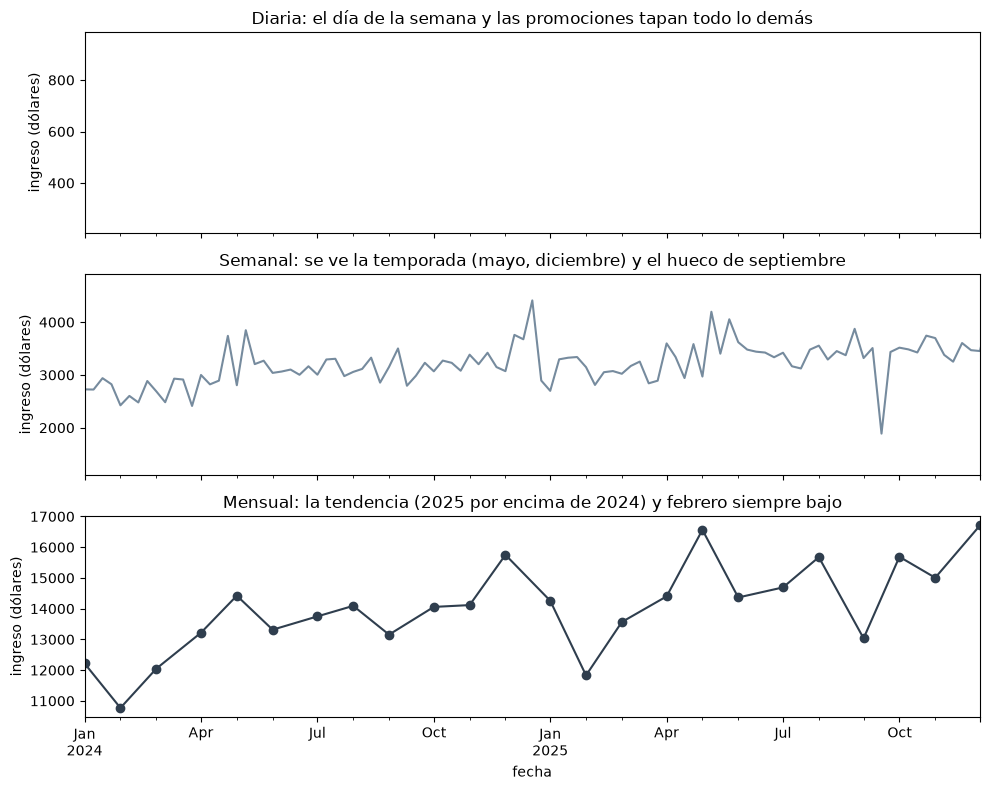

In [16]:
# La misma serie en tres frecuencias: diaria (ruido), semanal (temporada), mensual (tendencia)
fig, axes = plt.subplots(3, 1, figsize=(10, 8), sharex=True) # sharex es para que comparten el mismo eje de las x
d["ingreso"].plot(ax=axes[0], color="#A9B8C6", linewidth=0.8) # Mide en días (19 700 días)
axes[0].set_title("Diaria: el día de la semana y las promociones tapan todo lo demás")

# En realidad es .plot.line pero por defecto plot = plot.line
semanal.plot(ax=axes[1], color="#768B9E") # Mide en meses (648 meses)
axes[1].set_title("Semanal: se ve la temporada (mayo, diciembre) y el hueco de septiembre")

mensual.plot(ax=axes[2], color="#2F3E4E", marker="o")
axes[2].set_title("Mensual: la tendencia (2025 por encima de 2024) y febrero siempre bajo")

for ax in axes:
    ax.set_ylabel("ingreso (dólares)")
axes[2].set_xlabel("fecha")

fig.tight_layout()
plt.show()

Lectura: el mes con más ingreso es **2025-12** (16,708 dólares) y el más bajo, **2024-02**. En la diaria no se ve nada de eso.

**Contar eventos**: cuando cada fila es un hecho con fecha (una siembra, una entrega, una venta) y no un valor por día, `resample("ME").size()` cuenta cuántos hubo por mes.

### Su turno 3.1 · 5 min
En `cosechas.csv` cada fila es un ciclo con su `fecha_siembra`. Ponga la fecha como índice y calcule: `siembras_mes`, el **número de siembras por mes** (`resample("ME").size()`), y `peso_trim`, el **peso final promedio por trimestre** (`"QE"`, columna `peso_g`, `mean`). ¿En qué mes se sembró más? ¿Hay trimestres con camarón más pesado?

In [17]:
# TODO: reemplace los ... por su código
ct = c.set_index("fecha_siembra").sort_index()
siembras_mes = ct.resample("ME").size()
peso_trim = ct["peso_g"].resample("QE").mean()
print("mes con más siembras:", siembras_mes.idxmax().strftime("%Y-%m"), "con", siembras_mes.max(), "ciclos")
print(peso_trim.round(2))

mes con más siembras: 2024-12 con 39 ciclos
fecha_siembra
2024-03-31    19.83
2024-06-30    20.12
2024-09-30    19.31
2024-12-31    19.64
2025-03-31    20.08
2025-06-30    19.52
2025-09-30    19.98
2025-12-31    21.70
Freq: QE-DEC, Name: peso_g, dtype: float64


In [18]:
assert len(siembras_mes) == 22 and siembras_mes.max() == 39 and siembras_mes.idxmax().strftime("%Y-%m") == "2024-12", "ct.resample('ME').size()"
assert len(peso_trim) == 8 and np.isclose(round(peso_trim.max(), 2), 21.7), "ct['peso_g'].resample('QE').mean()"
print("Correcto:", siembras_mes.max(), "siembras en", siembras_mes.idxmax().strftime("%Y-%m"), "; el peso promedio por trimestre se mueve entre", round(peso_trim.min(), 1), "y", round(peso_trim.max(), 1), "g.")

Correcto: 39 siembras en 2024-12 ; el peso promedio por trimestre se mueve entre 19.3 y 21.7 g.


## 4. La tendencia detrás del ruido: medias móviles y crecimiento

Una **media móvil** (`rolling(7).mean()`) reemplaza cada valor por el promedio de los últimos 7 (una semana completa: así el efecto del día de la semana desaparece). Con `rolling(30, center=True)` la ventana se centra en cada fecha y la curva queda suave y sin retraso. Cuanto más ancha la ventana, más suave la curva y menos detalle.

Para **medir** el cambio: `diff()` (diferencia con el valor anterior), `pct_change()` (cambio porcentual con el anterior: mes contra mes) y `shift(12)` sobre la serie mensual (el mismo mes del año anterior: **año contra año**, que no se deja engañar por la temporada).

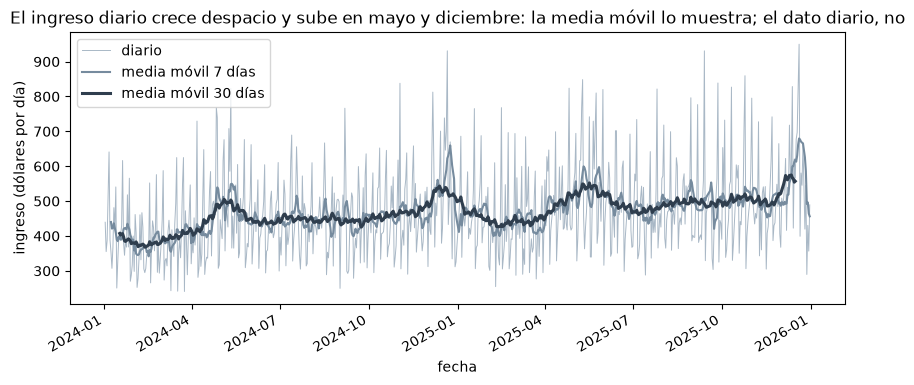

In [19]:
mm7 = d["ingreso"].rolling(7).mean()    # media de los últimos 7 días (los 6 primeros quedan NaN)
mm30 = d["ingreso"].rolling(30, center=True).mean()   # ventana de 30 días centrada

fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(d.index, d["ingreso"], color="#A9B8C6", linewidth=0.7, label="diario")
ax.plot(mm7.index, mm7, color="#768B9E", linewidth=1.5, label="media móvil 7 días")
ax.plot(mm30.index, mm30, color="#2F3E4E", linewidth=2.2, label="media móvil 30 días")

ax.set_xlabel("fecha")
ax.set_ylabel("ingreso (dólares por día)")
ax.set_title("El ingreso diario crece despacio y sube en mayo y diciembre: la media móvil lo muestra; el dato diario, no")

ax.legend()
fig.autofmt_xdate() # Alinea todo para que se vea bien (El eje x)

plt.show()

In [20]:
# Crecimiento mes contra mes (pct_change) y año contra año (shift(12) sobre la serie mensual)
crec_mes = (mensual.pct_change() * 100).round(1)                       # % respecto del mes anterior
crec_anual_mes = ((mensual / mensual.shift(12) - 1) * 100).round(1)    # % respecto del mismo mes del año anterior

tabla = pd.DataFrame({"ingreso": mensual.round(0), "vs_mes_anterior_%": crec_mes, "vs_mismo_mes_2024_%": crec_anual_mes})
tabla.tail(8)

,ingreso,vs_mes_anterior_%,vs_mismo_mes_2024_%
fecha,,,
2025-05-31,16564.0,15.0,14.9
2025-06-30,14364.0,-13.3,7.9
2025-07-31,14691.0,2.3,6.9
2025-08-31,15676.0,6.7,11.2
2025-09-30,13035.0,-16.8,-0.9
2025-10-31,15687.0,20.3,11.6
2025-11-30,15006.0,-4.3,6.3
2025-12-31,16708.0,11.3,6.1


Lectura: mes contra mes, el mayor salto es **2025-10** (+20.3 %), pero es temporada (viene de un mes bajo). Año contra año, 2025 queda por encima de 2024 casi todos los meses: eso sí es **crecimiento**.

### Su turno 4.1 · 4 min
Calcule `mm14`, la media móvil de **14 días** del ingreso diario (`d["ingreso"]`), y `crec_anual`, el crecimiento del ingreso total de 2025 frente a 2024 en porcentaje (sugerencia: `anual = d["ingreso"].resample("YE").sum()` y después `anual.iloc[1] / anual.iloc[0]`).

In [21]:
# TODO: reemplace los ... por su código
mm14 = d["ingreso"].rolling(14).mean()
anual = d["ingreso"].resample("YE").sum()
crec_anual = (anual.iloc[1] / anual.iloc[0] - 1) * 100
print("máximo de la media móvil de 14 días:", round(mm14.max(), 2), "dólares")
print("ingreso 2024:", round(anual.iloc[0]), "| 2025:", round(anual.iloc[1]), "| crecimiento:", round(crec_anual, 1), "%")

máximo de la media móvil de 14 días: 643.2 dólares
ingreso 2024: 160907 | 2025: 175783 | crecimiento: 9.2 %


In [22]:
assert np.isclose(round(mm14.max(), 2), 643.2), "d['ingreso'].rolling(14).mean()"
assert np.isclose(round(crec_anual, 1), 9.2), "(anual.iloc[1] / anual.iloc[0] - 1) * 100"
print("Correcto: 2025 vendió", round(crec_anual, 1), "% más que 2024; la media móvil de 14 días toca su máximo en diciembre de 2025.")

Correcto: 2025 vendió 9.2 % más que 2024; la media móvil de 14 días toca su máximo en diciembre de 2025.


## 5. Estacionalidad a simple vista: el patrón que se repite

**Estacionalidad** es lo que se repite con un periodo fijo: cada semana (el sábado vende más), cada año (diciembre). Se ve agrupando por la parte de la fecha que se repite:

- por **día de la semana**: `groupby(d.index.dayofweek)` → el promedio de cada día;
- por **mes**: una tabla mes × año (`pivot_table`) y una línea por año: si las líneas tienen la misma forma, hay temporada;
- un **evento** (promoción, feriado) se compara con los días normales.

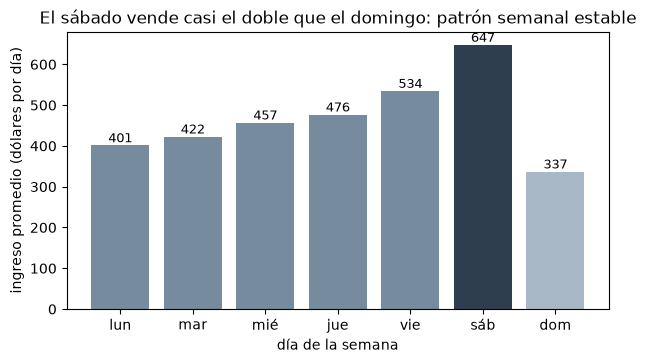

In [ ]:
por_dia = d.groupby(d.index.dayofweek)["ingreso"].mean()   # Agrupa por día

fig, ax = plt.subplots(figsize=(7, 3.6))
ax.bar(DIAS, por_dia, color=["#768B9E"] * 5 + ["#2F3E4E", "#A9B8C6"]) 
# 1. Multiplica el color 5 veces (lista con 5 elementos) [#768B9E, #768B9E, #768B9E, #768B9E, #768B9E]
# 2. Concatena los últimos (+) [#768B9E, #768B9E, #768B9E, #768B9E, #768B9E, "#2F3E4E", "#A9B8C6"]

# Poniendo números encima de cada barra
for i, valor in enumerate(por_dia):
    ax.text(i, valor + 8, f"{valor:.0f}", ha="center", fontsize=9)

ax.set_xlabel("día de la semana")
ax.set_ylabel("ingreso promedio (dólares por día)")
ax.set_title("El sábado vende casi el doble que el domingo: patrón semanal estable")

plt.show()

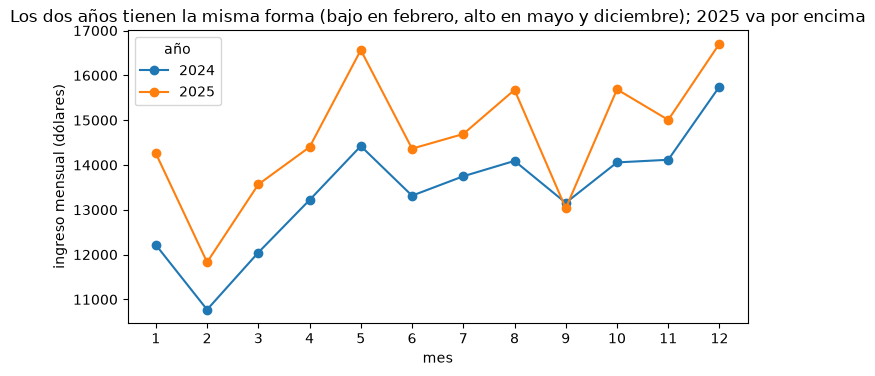

mes,1,2,3,4,5,6,7,8,9,10,11,12
anio,,,,,,,,,,,,
2024,12216.0,10771.0,12046.0,13218.0,14422.0,13315.0,13748.0,14091.0,13155.0,14057.0,14116.0,15751.0
2025,14258.0,11830.0,13566.0,14399.0,16564.0,14364.0,14691.0,15676.0,13035.0,15687.0,15006.0,16708.0


In [ ]:
# Mes x año: una línea por año. Misma forma = temporada; una línea por encima = tendencia
tabla_mes = d.pivot_table(index="mes", columns="anio", values="ingreso", aggfunc="sum").round(0)

fig, ax = plt.subplots(figsize=(8, 3.8))
for anio in tabla_mes.columns:
    ax.plot(tabla_mes.index, tabla_mes[anio], marker="o", label=str(anio))
    
ax.set_xticks(range(1, 13))
ax.set_xlabel("mes")
ax.set_ylabel("ingreso mensual (dólares)")
ax.set_title("Los dos años tienen la misma forma (bajo en febrero, alto en mayo y diciembre); 2025 va por encima")
ax.legend(title="año")
plt.show()

tabla_mes.T # La transpuesta de tabla mes (Para que sea leíble)


In [55]:
# Un evento: los 36 días con promoción frente a los días normales
d.groupby("promocion")["ingreso"].agg(["mean", "median", "size"]).round(1)

,mean,median,size
promocion,,,
0,460.5,440.5,684
1,602.2,579.8,36


### Su turno 5.1 · 5 min
En `entregas.csv` (`e`, 420 entregas de julio y agosto): ¿qué **día de la semana** tiene más entregas y cuál tiene la **mediana de tiempo** más alta? Guarde en `entregas_dia` el número de entregas por día de la semana (`groupby` por `.dt.dayofweek` + `size()`) y en `tiempo_dia` la mediana de `tiempo_min` por día de la semana. Dibuje `entregas_dia` como barras con los nombres de `DIAS`.

In [26]:
e

,id_entrega,fecha,ciudad,tipo_servicio,peso_kg,distancia_km,tiempo_min,costo,calificacion
0,E-0001,2026-07-01,Guayaquil,express,2.09,15.4,91,13.82,1
1,E-0002,2026-07-01,Guayaquil,estándar,0.56,9.8,68,7.29,2
2,E-0003,2026-07-01,Guayaquil,estándar,3.60,5.9,35,7.33,5
3,E-0004,2026-07-01,Manta,estándar,1.57,8.2,63,7.33,5
4,E-0005,2026-07-01,Cuenca,estándar,3.39,5.9,38,7.69,4
...,...,...,...,...,...,...,...,...,...
415,E-0416,2026-08-31,Ambato,estándar,0.76,5.2,48,5.30,1
416,E-0417,2026-08-31,Guayaquil,estándar,0.49,12.3,74,8.12,5
417,E-0418,2026-08-31,Quito,estándar,1.81,6.2,52,6.67,5
418,E-0419,2026-08-31,Guayaquil,estándar,0.33,3.8,35,3.82,4


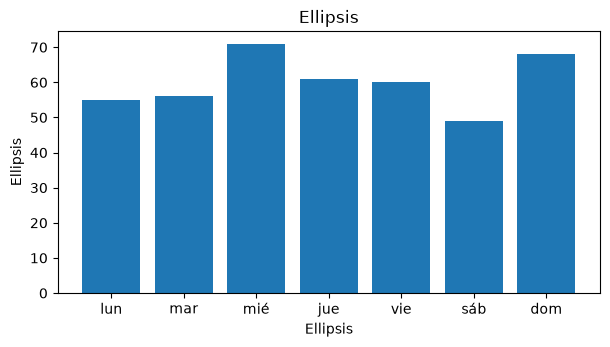

día con más entregas: mié | día con la mediana de tiempo más alta: jue con 64.0 min


In [56]:
# TODO: reemplace los ... por su código
entregas_dia = e.groupby(e["fecha"].dt.dayofweek).size()
tiempo_dia = e.groupby(e["fecha"].dt.dayofweek)["tiempo_min"].median()
fig, ax = plt.subplots(figsize=(7, 3.4))
ax.bar(DIAS, entregas_dia)
ax.set_xlabel(...)
ax.set_ylabel(...)
ax.set_title(...)
plt.show()
print("día con más entregas:", DIAS[entregas_dia.idxmax()], "| día con la mediana de tiempo más alta:", DIAS[tiempo_dia.idxmax()], "con", tiempo_dia.max(), "min")

In [28]:
assert len(entregas_dia) == 7 and entregas_dia.max() == 71 and entregas_dia.idxmax() == 2, "e.groupby(e['fecha'].dt.dayofweek).size()"
assert np.isclose(round(tiempo_dia.max(), 1), 64.0) and tiempo_dia.idxmax() == 3, "groupby(...)['tiempo_min'].median()"
assert ax.get_xlabel() != "" and ax.get_ylabel() != "" and ax.get_title() != "", "faltan etiquetas o título"
print("Correcto: el", DIAS[entregas_dia.idxmax()], "tiene más entregas (", entregas_dia.max(), ") y el", DIAS[tiempo_dia.idxmax()], "la mediana de tiempo más alta (", tiempo_dia.max(), "min).")

Correcto: el mié tiene más entregas ( 71 ) y el jue la mediana de tiempo más alta ( 64.0 min).


## 6. El gráfico de una serie de tiempo

La serie va en **líneas** (el tiempo es continuo), la fecha en el eje x. Reglas:

- `ax.plot(serie.index, serie)` o el atajo `serie.plot(ax=ax)`; `fig.autofmt_xdate()` inclina las fechas para que no se monten;
- el eje y **con unidad**; si se comparan series, la misma escala;
- la serie cruda en gris claro y la media móvil encima, oscura: el lector ve el ruido y la tendencia;
- los **eventos** se marcan: `ax.axvspan(inicio, fin)` sombrea un periodo; `ax.axvline(fecha)` marca un día; `ax.annotate` pone el texto con una flecha;
- el **título dice la conclusión** («diciembre dobla a febrero»), no el nombre de las columnas (sesión 13).

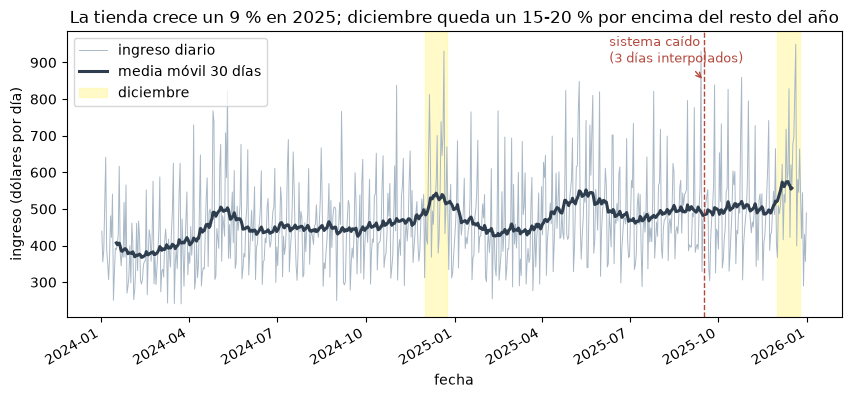

In [72]:
fig, ax = plt.subplots(figsize=(10, 4.2))
ax.plot(d.index, d["ingreso"], color="#A9B8C6", linewidth=0.7, label="ingreso diario")
ax.plot(mm30.index, mm30, color="#2F3E4E", linewidth=2.2, label="media móvil 30 días")

# Sombrear los dos diciembres (Picos), sin contar 2024
for anio in (2024, 2025):           
    ax.axvspan(pd.Timestamp(f"{anio}-12-01"), pd.Timestamp(f"{anio}-12-24"), color="#FFF9B0", alpha=0.7, label="diciembre" if anio == 2024 else None)

# Mencionar días interpolados
ax.axvline(pd.Timestamp("2025-09-16"), color="#B4483C", linestyle="--", linewidth=1)
ax.annotate("sistema caído\n(3 días interpolados)", xy=(pd.Timestamp("2025-09-16"), 850), xytext=(pd.Timestamp("2025-06-10"), 900),
            arrowprops=dict(arrowstyle="->", color="#B4483C"), fontsize=9, color="#B4483C")

ax.set_xlabel("fecha")
ax.set_ylabel("ingreso (dólares por día)")
ax.set_title("La tienda crece un 9 % en 2025; diciembre queda un 15-20 % por encima del resto del año")
ax.legend(loc="upper left")
fig.autofmt_xdate()

os.makedirs("figuras", exist_ok=True)
fig.savefig("figuras/s12_ingreso_diario.png", dpi=150, bbox_inches="tight")  # Para un informe: 150 dpi, antes de plt.show()

plt.show()

### Su turno 6.1 · 4 min
Dibuje la serie **semanal** (`semanal`, de la sección 3) como línea, marque con `ax.axvline` las dos semanas del Día de la Madre (`"2025-05-11"` y `"2024-05-12"`) y ponga título con la conclusión y etiquetas con unidad. ¿Qué semana es la más alta de los dos años?

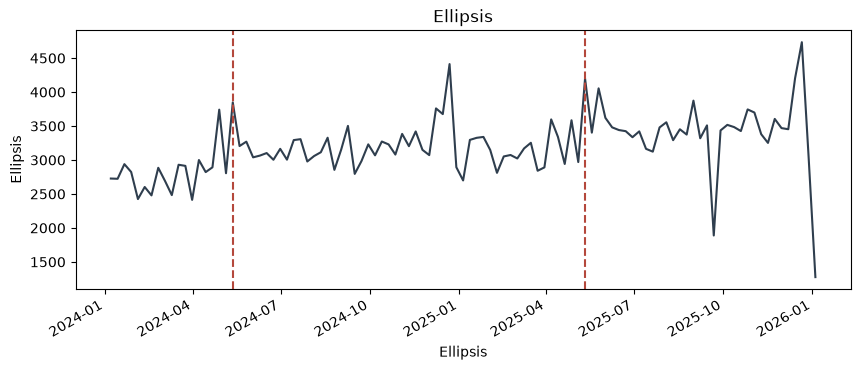

semana más alta: 2025-12-21 con 4733.77 dólares


In [30]:
# TODO: reemplace los ... por su código
fig, ax = plt.subplots(figsize=(10, 3.8))
ax.plot(semanal.index, semanal, color="#2F3E4E", linewidth=1.5, label="ingreso semanal")
ax.axvline(pd.Timestamp("2024-05-12"), color="#B4483C", linestyle="--")
ax.axvline(pd.Timestamp("2025-05-11"), color="#B4483C", linestyle="--")
ax.set_xlabel(...)
ax.set_ylabel(...)
ax.set_title(...)
fig.autofmt_xdate()
plt.show()
semana_top = semanal.idxmax()
print("semana más alta:", semana_top.date(), "con", round(semanal.max(), 2), "dólares")

In [73]:
assert len(ax.lines) >= 3, "la serie semanal con ax.plot y dos ax.axvline"
assert ax.get_xlabel() != "" and ax.get_ylabel() != "" and ax.get_title() != "", "faltan etiquetas o título"
assert str(semana_top.date()) == "2025-12-21", "semanal.idxmax()"
print("Correcto: la semana más alta cierra el", semana_top.date(), "con", round(semanal.max(), 2), "dólares.")

Correcto: la semana más alta cierra el 2025-12-21 con 4733.77 dólares.


## 7. Errores frecuentes

| Síntoma | Causa | Solución |
| :-- | :-- | :-- |
| `.dt` da `AttributeError: Can only use .dt accessor with datetimelike values` | la columna sigue siendo texto | `parse_dates=[...]` al leer o `pd.to_datetime(col, format=...)` |
| las fechas salen cambiadas (9 de noviembre → 11 de septiembre) | formato día/mes/año leído como mes/día/año | `pd.to_datetime(col, format="%d/%m/%Y")` |
| `resample` da `TypeError: Only valid with DatetimeIndex` | la fecha no es el índice | `df.set_index("fecha").sort_index()` o `df.resample("ME", on="fecha")` |
| `resample("M")` avisa o falla | alias antiguo | use `"ME"` (fin de mes), `"QE"`, `"YE"` |
| la serie mensual tiene un mes casi vacío al principio o al final | el primer o el último mes está incompleto | recorte los meses incompletos o diga que lo están |
| la media móvil empieza con `NaN` | la ventana necesita 7 valores | normal; `min_periods=1` si quiere valores desde el inicio |
| un pico enorme en el gráfico mensual | varios archivos con fechas duplicadas, o un día cargado dos veces | `d.index.duplicated().sum()`, `drop_duplicates` antes de `set_index` |
| `pct_change` de un mes bajo da +40 % | temporada, no crecimiento | compare año contra año (`shift(12)`) |
| línea que une puntos separados por meses | huecos en la serie | `asfreq("D")` deja `NaN` y matplotlib corta la línea; o `interpolate` y dígalo |

## 8. Hacia el proyecto: la serie de tiempo de la Entrega 1

La **Entrega 1** (sesión 14, semana del 16 de noviembre) tiene una sección de **serie de tiempo** (sección 7 del informe) para los grupos cuya tabla tiene fecha. Con lo de hoy:

| Pregunta del proyecto | Herramienta | Qué entregar |
| :-- | :-- | :-- |
| «¿cómo cambia x con el tiempo?» | fecha como índice + `resample` a la frecuencia que responda la pregunta (semana, mes, año) | la serie en líneas, con unidad, y **una frase** con la tendencia (crece, baja, estable) y un número |
| «¿crece de verdad o es temporada?» | media móvil + comparación año contra año (`shift(12)`) | la media móvil sobre la serie, el % año contra año |
| «¿hay un patrón que se repite?» | promedio por día de la semana o por mes (`groupby` por la parte de la fecha; tabla mes × año) | barras por día de la semana o líneas por año, y una frase |
| «¿qué pasó en esa fecha?» | selección por rango + `axvspan` / `annotate` | el evento marcado en el gráfico y explicado en el texto |
| la tabla **no tiene fecha** | no hay serie de tiempo | el informe lo dice; la sección 7 compara la variable principal a lo largo de una variable ordinal o secuencial (edad, nivel, orden), o se omite con justificación (ver el enunciado) |

### Su turno 8.1 · en casa
Con la tabla limpia del grupo (si tiene fecha): ponga la fecha como índice, construya la serie a la frecuencia que responda una de sus preguntas (`resample`), dibújela con su media móvil y escriba una frase con un número. Añada el patrón que se repite (día de la semana o mes). Si el grupo **no** tiene fecha, haga la comparación a lo largo de su variable ordinal o secuencial. Traiga el notebook a la sesión 13: dos grupos lo muestran.

In [32]:
# Con su conjunto de datos (complete con sus columnas)
# datos = pd.read_csv("datos/mi_dataset_limpio.csv", parse_dates=["fecha"])
# s = datos.set_index("fecha").sort_index()
# serie = s["columna"].resample("ME").sum()              # o .mean(), .size(); "W" si la pregunta es semanal
# mm = serie.rolling(3, center=True).mean()             # ventana según la frecuencia (3 meses, 7 días, ...)
# fig, ax = plt.subplots(figsize=(9, 3.8)); ax.plot(serie.index, serie, color="#A9B8C6"); ax.plot(mm.index, mm, color="#2F3E4E")
# ax.set_xlabel("fecha"); ax.set_ylabel("... (unidad)"); ax.set_title("... la conclusión ..."); fig.autofmt_xdate()
# por_dia = s.groupby(s.index.dayofweek)["columna"].mean()   # o por mes: s.groupby(s.index.month)

**Antes de la próxima sesión (S13, esta misma semana):** visualización efectiva (tema 3.6): qué gráfico para qué pregunta, ejes honestos, color con intención, títulos que dicen la conclusión, seaborn y «arregla este gráfico». **La Tarea 2 se entrega al inicio de la S13.** El enunciado de la **Entrega 1** (informe + notebook, sesión 14) ya está en el aula virtual: léalo antes de la S13. Lecturas: McKinney cap. 11 (§11.1–11.3, §11.6–11.7); VanderPlas cap. 3, «Working with Time Series».